# 04. Estádio e tipo histológico

Em que fase da doença o câncer de mama é descoberto? Esta é a pergunta central para o TCC, porque o diagnóstico tardio é justamente o problema que tecnologias de detecção e monitoramento mais acessíveis poderiam ajudar a reduzir.

O estádio vai de 0 a IV. O estádio 0 é o carcinoma in situ, ainda restrito ao ducto ou lóbulo. Os estádios I e II são tumores menores, com pouco ou nenhum comprometimento de linfonodos. O estádio III é um tumor localmente avançado. O estádio IV significa que já há metástase à distância. Seguindo a literatura brasileira, chamamos de estádio avançado os estádios III e IV.

A fonte é o RHC. Como cerca de um terço dos casos fora do Sudeste não tem estádio registrado, todos os percentuais de estádio avançado são calculados entre os casos com estádio conhecido.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mama import codigos as c, graficos as g, harmonizacao as h
from mama.config import FONTE_RHC
from mama.analises import base, perfil, estadiamento as est

pd.set_option("display.max_columns", 20)
rhc = base.rhc()
rhc["grupo_idade"] = h.grupo_50(rhc.idade)
print(f"{len(rhc):,} mulheres (casos analíticos do RHC, 2013 a 2022)")

351,299 mulheres (casos analíticos do RHC, 2013 a 2022)


## Distribuição dos estádios por região

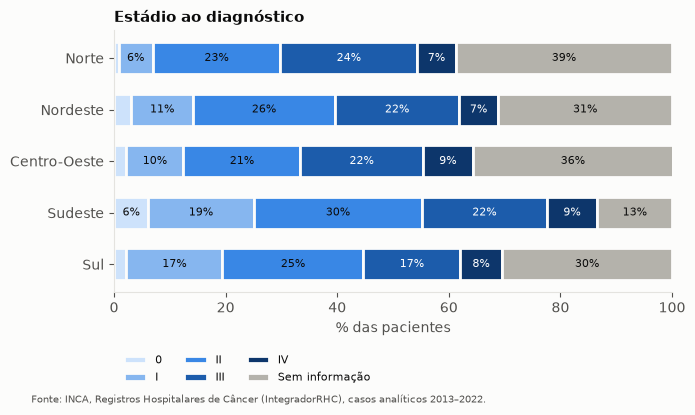

estadio_rotulo,0,I,II,III,IV,Sem informação
regiao_res,,,,,,
Norte,0.8,6.1,22.9,24.5,6.9,38.8
Nordeste,3.1,11.0,25.5,22.2,7.0,31.2
Centro-Oeste,2.2,10.2,21.0,21.9,9.0,35.8
Sudeste,6.1,18.9,30.2,22.3,9.1,13.4
Sul,2.2,17.2,25.3,17.3,7.5,30.5


In [2]:
dist = est.distribuicao_estadio(rhc)
base.salvar_tabela(dist, "04_distribuicao_estadio_regiao", index=True)
cores_estadio = {"0": "#cde2fb", "I": "#86b6ef", "II": "#3987e5", "III": "#1c5cab", "IV": "#0d366b", c.SEM_INFO: g.CINZA}
fig, ax = g.empilhadas_100(dist, "Estádio ao diagnóstico", cores=cores_estadio)
g.salvar(fig, "04_distribuicao_estadio_regiao", FONTE_RHC)
plt.show()
dist

As cores vão do claro (estádio 0) ao escuro (estádio IV), e o cinza é a falta de informação. O Sudeste tem a maior fatia de estádios iniciais, 0 a II, e a menor de casos sem estádio. No Norte, o estádio III, sozinho, é tão frequente quanto o II.

## Estádio avançado por estado

O mapa mostra, para cada estado, o percentual de casos em estádio III ou IV entre os que têm estádio informado.

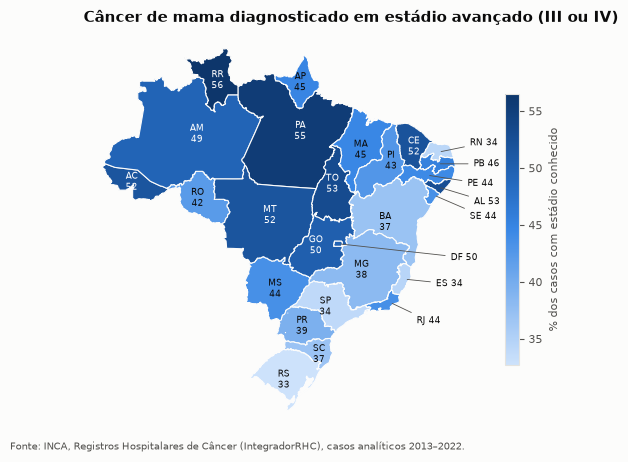

In [3]:
por_uf = est.avancado(rhc, ["uf_res"])
base.salvar_tabela(por_uf, "04_estadio_avancado_uf")
fig, ax = g.mapa_uf(por_uf.set_index("uf_res").pct, "Câncer de mama diagnosticado em estádio avançado (III ou IV)",
                    "% dos casos com estádio conhecido")
g.salvar(fig, "04_mapa_estadio_avancado_uf", FONTE_RHC)
plt.show()

O padrão geográfico é claro e reproduz o que Oliveira e colaboradores (2021) encontraram, figura 1 do projeto: os estados do Norte e do Centro-Oeste concentram os maiores percentuais, acima de 50% em Roraima, Pará, Tocantins e Acre, enquanto Rio Grande do Sul, São Paulo e Espírito Santo ficam em torno de um terço. Em Roraima e no Amapá o número de casos é pequeno (menos de 250 com estádio no período), então o valor exato desses dois estados é mais instável.

## Separando por tipo histológico

O tipo histológico descreve a aparência do tumor ao microscópio. O carcinoma ductal invasivo responde por três quartos dos casos, o lobular por cerca de 4%, e o restante se divide em tipos menos comuns ou sem especificação. Os mapas abaixo usam a mesma escala de cor, para que possam ser comparados diretamente. Estados com menos de 100 casos com estádio em um tipo ficam em cinza.

Tipo histológico não é o mesmo que subtipo molecular (luminal, HER2 positivo, triplo-negativo). O subtipo molecular depende de exames de imuno-histoquímica que o RHC não registra. Ele é estimado no caderno 05, com outra fonte.

histologia,Carcinoma ductal,Carcinoma lobular,Outros tipos
regiao_res,,,
Norte,76.7,2.2,21.1
Nordeste,80.3,3.0,16.7
Centro-Oeste,75.3,4.1,20.6
Sudeste,75.2,5.5,19.3
Sul,71.3,4.3,24.4


,histologia,n,eventos,pct,ic_inf,ic_sup
0,Carcinoma ductal,208176,81659,39.2,39.0,39.4
1,Carcinoma lobular,12585,4700,37.3,36.5,38.2
2,Outros tipos,47914,17205,35.9,35.5,36.3


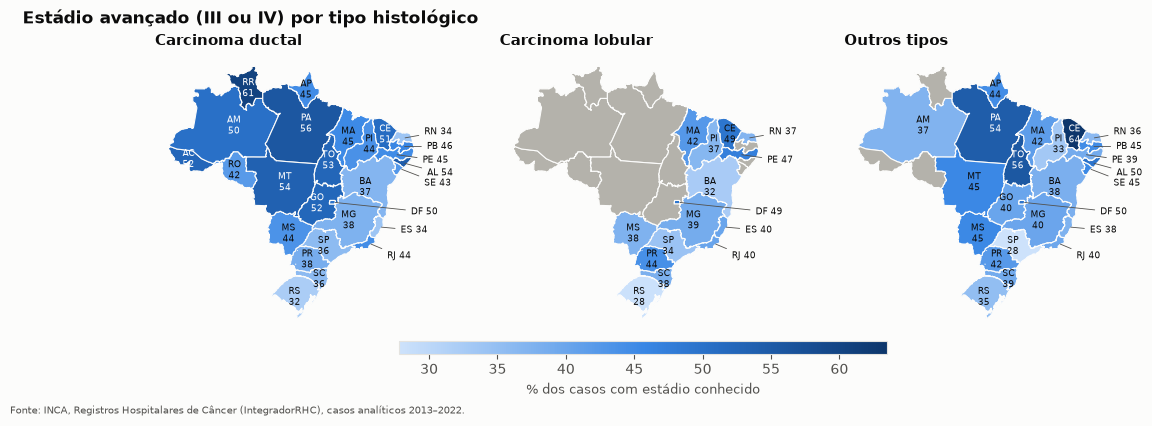

In [4]:
display(base.distribuicao(rhc, "histologia", ordem=c.HISTOLOGIA_ORDEM))
display(est.avancado(rhc, ["histologia"]))
mapas = est.avancado_por_histologia_uf(rhc)
fig, axes = g.mapas_uf_multiplos(mapas, "Estádio avançado (III ou IV) por tipo histológico",
                                 "% dos casos com estádio conhecido")
g.salvar(fig, "04_mapas_estadio_avancado_histologia", FONTE_RHC)
plt.show()

O carcinoma ductal, que concentra a maior parte dos casos, reproduz o gradiente geográfico do mapa geral, com Norte e Centro-Oeste mais escuros. O grupo de outros tipos segue o mesmo desenho, com Ceará, Tocantins e Pará entre os mais altos. Isso indica que a diferença entre regiões não se explica pelo tipo de tumor, e sim pelo momento em que ele é descoberto. O carcinoma lobular é raro demais para essa comparação: no Norte e em parte do Centro-Oeste não há casos suficientes, e os estados com dados ficam todos entre 28% e 49%.

## Idade: antes e depois dos 50 anos

Mulheres abaixo de 50 anos estão fora da faixa do rastreamento. O gráfico mostra o percentual de estádio avançado nos dois grupos de idade, em cada região. As linhas horizontais em volta de cada ponto são intervalos de confiança de 95%: indicam a margem de incerteza do percentual. Quando as linhas de dois pontos não se sobrepõem, a diferença entre eles dificilmente é obra do acaso.

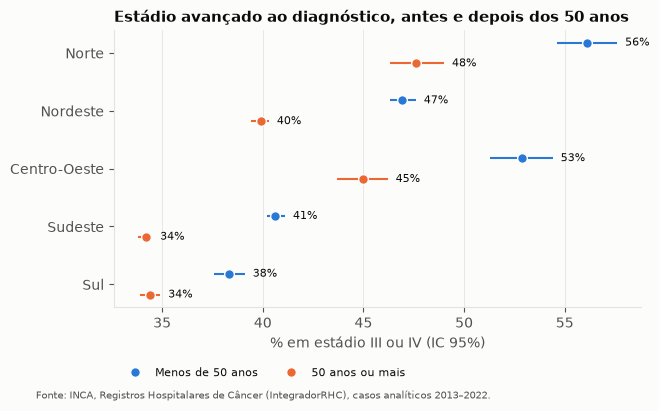

,faixa_etaria,n,eventos,pct,ic_inf,ic_sup
0,<40,29301,14369,49.0,48.5,49.6
1,40-49,62608,25166,40.2,39.8,40.6
2,50-69,132607,47370,35.7,35.5,36.0
3,70+,44153,16654,37.7,37.3,38.2


In [5]:
t_idade = est.avancado(rhc, ["regiao_res", "grupo_idade"])
base.salvar_tabela(t_idade, "04_estadio_avancado_regiao_idade50")
fig, ax = g.pontos_ic(t_idade, "regiao_res", "grupo_idade", "Estádio avançado ao diagnóstico, antes e depois dos 50 anos",
                      "% em estádio III ou IV (IC 95%)", ordem_cat=c.REGIOES,
                      ordem_grupo=["Menos de 50 anos", "50 anos ou mais"],
                      cores={"Menos de 50 anos": g.CATEGORICAS[0], "50 anos ou mais": g.CATEGORICAS[1]})
g.salvar(fig, "04_estadio_avancado_idade50", FONTE_RHC)
plt.show()
t_faixa = est.avancado(rhc, ["faixa_etaria"])
base.salvar_tabela(t_faixa, "04_estadio_avancado_faixa_etaria")
t_faixa

Em todas as regiões, as mulheres com menos de 50 anos chegam com estádio avançado com mais frequência do que as mais velhas. A tabela por faixa etária mostra que o efeito é mais forte abaixo dos 40 anos: 49% de estádio avançado, contra 36% entre 50 e 69 anos. Duas explicações se somam e são discutidas na literatura citada no projeto: essas mulheres não são alcançadas pelo rastreamento, e nelas são mais comuns subtipos biologicamente mais agressivos (ver caderno 05).

## Raça/cor

Como a composição racial difere muito entre regiões, comparar raça/cor no país inteiro misturaria o efeito da raça com o da região. Por isso a comparação é feita dentro de cada região. São Paulo é excluído pela falta de preenchimento.

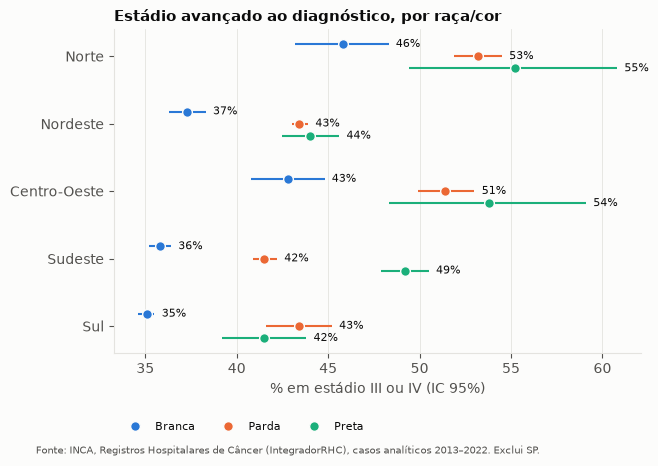

In [6]:
sem_sp = rhc[(rhc.uf_res != "SP") & rhc.raca_cor.isin(["Branca", "Parda", "Preta"])]
t_raca = est.avancado(sem_sp, ["regiao_res", "raca_cor"])
base.salvar_tabela(t_raca, "04_estadio_avancado_regiao_raca")
fig, ax = g.pontos_ic(t_raca, "regiao_res", "raca_cor", "Estádio avançado ao diagnóstico, por raça/cor",
                      "% em estádio III ou IV (IC 95%)", ordem_cat=c.REGIOES, ordem_grupo=["Branca", "Parda", "Preta"],
                      figsize=(6.8, 4.2))
g.salvar(fig, "04_estadio_avancado_raca", FONTE_RHC + " Exclui SP.")
plt.show()

Dentro de cada região, mulheres pretas e pardas são diagnosticadas em estádio avançado com mais frequência do que mulheres brancas. No Sudeste, a diferença chega a 13 pontos percentuais entre mulheres pretas e brancas. No Sul, é de 8 pontos entre pardas e brancas. Como a comparação é feita dentro da mesma região, a diferença não se explica pela geografia, e é coerente com a literatura sobre desigualdade racial no acesso ao diagnóstico.

## Escolaridade

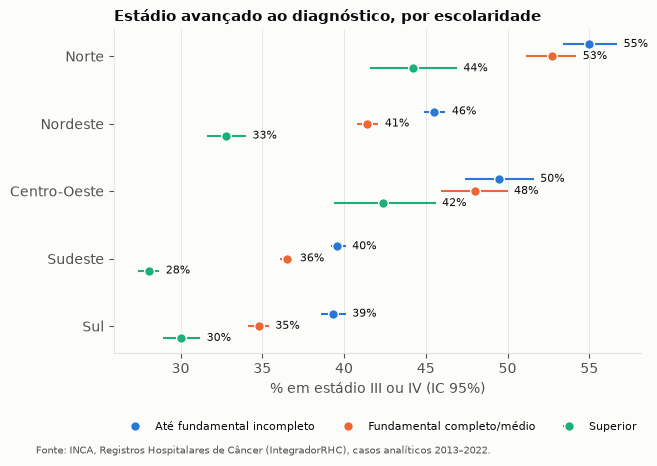

In [7]:
t_esc = est.avancado(rhc[rhc.escolaridade_grupo != c.SEM_INFO], ["regiao_res", "escolaridade_grupo"])
base.salvar_tabela(t_esc, "04_estadio_avancado_regiao_escolaridade")
fig, ax = g.pontos_ic(t_esc, "regiao_res", "escolaridade_grupo", "Estádio avançado ao diagnóstico, por escolaridade",
                      "% em estádio III ou IV (IC 95%)", ordem_cat=c.REGIOES, ordem_grupo=c.ESCOLARIDADE_GRUPO_ORDEM,
                      figsize=(6.8, 4.2))
g.salvar(fig, "04_estadio_avancado_escolaridade", FONTE_RHC)
plt.show()

O padrão se repete em todas as regiões: quanto maior a escolaridade, menor o percentual de estádio avançado. No Nordeste, por exemplo, ele cai de 46% entre mulheres até o fundamental incompleto para 33% entre as que chegaram ao ensino superior. A escolaridade funciona aqui como um indicador de renda e de acesso à informação e aos serviços.

## Evolução ao longo do tempo

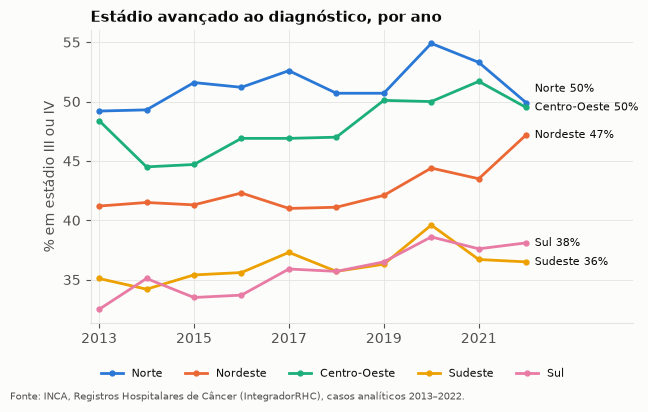

In [8]:
t_ano = est.avancado(rhc, ["ano_consulta", "regiao_res"]).rename(columns={"regiao_res": "regiao"})
base.salvar_tabela(t_ano, "04_estadio_avancado_ano_regiao")
fig, ax = g.linhas(t_ano, "ano_consulta", "pct", "regiao", "Estádio avançado ao diagnóstico, por ano",
                   "% em estádio III ou IV", fmt="{:.0f}%", ordem=c.REGIOES)
g.salvar(fig, "04_estadio_avancado_tendencia", FONTE_RHC)
plt.show()

No país como um todo, o percentual de estádio avançado subiu de 37% em 2013 para 40% em 2022, com um salto em 2020: com a pandemia, consultas e mamografias foram adiadas, e os tumores foram descobertos mais tarde. O Norte oscila mais porque tem menos casos e porque a cobertura do RHC na região mudou ao longo do período (ver caderno 01). O ponto central é que, em dez anos, a distância entre Norte e Sul não diminuiu.

## O que levar para o TCC

Cerca de metade das mulheres do Norte e do Centro-Oeste chega ao hospital com estádio III ou IV, contra pouco mais de um terço no Sul e no Sudeste. A desvantagem é maior para mulheres com menos de 50 anos, mulheres pretas e pardas e mulheres com menor escolaridade, e aparece dentro de todas as regiões. O padrão vale para os diferentes tipos histológicos. Esses resultados sustentam a justificativa do projeto: há uma parcela grande de diagnósticos tardios, concentrada em grupos e regiões com menos acesso.